# Triple-Barrier Parameter Analysis

This notebook provides a workflow for analyzing and visualizing the choice of parameters for the Triple-Barrier labeling method.

The process is as follows:
1. **Load Execution Price Data**: Fetch the realistic bid/ask execution prices for a given market and date range.
2. **Calculate & Visualize Volatility**: Compute a rolling volatility measure from the historical data, which will be used to set dynamic barriers.
3. **Define Barriers & Generate Labels**: Use the calculated volatility to define the triple barriers and generate the resulting labels.
4. **Analyze Label Distribution**: Summarize and plot the distribution of outcomes (Win, Loss, Timeout) to understand the impact of the chosen parameters.

## Setup

Import libraries and define the core parameters for the analysis.

In [ ]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from numba import jit

from qate.core.model import Market, ExchangeName, Symbol
from qate.env import sys_env
from qate.store.parquet_store import ParquetStore
from qate.util.dt_range import DtRange

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
sns.set_style("whitegrid")
%matplotlib inline

PARQUET_STORE_ROOT_DIR = sys_env.get_parquet_root_dir()
MARKET = Market(ExchangeName.GMO, Symbol.XRP_JPY)
EXECUTION_SIZE = "150"
TIMEZONE = 'Asia/Tokyo' # Define the local timezone for analysis

DATA_START_DATE = "2025-09-01"
DATA_END_DATE = "2025-09-07"

start_dt_aware = pd.Timestamp(f"{DATA_START_DATE} 00:00:00", tz=TIMEZONE)
end_dt_aware = pd.Timestamp(f"{DATA_END_DATE} 23:59:59", tz=TIMEZONE)
DATA_DT_RANGE = DtRange(start_dt_aware, end_dt_aware)

VOLATILITY_LOOKBACK_MINUTES = 60 # Use a 1-hour window for rolling volatility
BARRIER_MULTIPLIER = 2.0 # Set barriers at 2.0x the rolling volatility
TIMEOUT_SEC = 45 # Set a 45-second timeout for the vertical barrier
TIMEOUT_DELTA = pd.Timedelta(seconds=TIMEOUT_SEC)
LABEL_RESAMPLE_INTERVAL = '1s'  # Resample interval for label generation (reduces computation)

print(f"Setup complete. Analysis range: {start_dt_aware} to {end_dt_aware}")

Setup complete. Analysis range: 2025-09-01 00:00:00+09:00 to 2025-09-01 23:59:59+09:00


## 1. Load Execution Price Data

Load the execution price data which contains the realistic bid, ask, and mid prices for our chosen market and order size.

In [2]:
vol_read_start_dt = start_dt_aware - pd.Timedelta(minutes=VOLATILITY_LOOKBACK_MINUTES)
load_range = DtRange(vol_read_start_dt, end_dt_aware)

print(f"Loading execution prices for {MARKET.id} (size: {EXECUTION_SIZE})...")
price_store = ParquetStore(PARQUET_STORE_ROOT_DIR).create_execution_price(MARKET, execution_size_str=EXECUTION_SIZE)
df = price_store.read(load_range)

if 'ts' in df.columns:
    # Ensure the 'ts' column is numeric, coercing errors to NaN
    df['ts'] = pd.to_numeric(df['ts'], errors='coerce')
    # Drop rows where 'ts' could not be converted to a numeric value
    df.dropna(subset=['ts'], inplace=True)

    # Convert to DatetimeIndex - use .dt accessor for Series timezone conversion
    df.index = pd.to_datetime(df['ts'], unit='s', utc=True).dt.tz_convert(TIMEZONE)
    df = df.drop(columns=['ts'])

if df.empty:
    print(f"Loaded {len(df)} data points.")
else:
    print(f"Loaded {len(df)} data points from {df.index.min()} to {df.index.max()}.")
df.head()

Loading execution prices for GMO:XRP_JPY (size: 150)...
Loaded 182902 data points from 2025-08-31 23:00:00.494999886+09:00 to 2025-09-01 23:59:58.792999983+09:00.


,bid,ask,mid,spread,spread_bps
ts,,,,,
2025-08-31 23:00:00.494999886+09:00,413.628000,413.829000,413.7285,0.201000,4.858258
2025-08-31 23:00:01+09:00,413.696667,413.815333,413.7560,0.118667,2.868035
2025-08-31 23:00:01.505000114+09:00,413.594000,413.863000,413.7285,0.269000,6.501848
2025-08-31 23:00:02.010999918+09:00,413.626000,413.863000,413.7445,0.237000,5.728173
2025-08-31 23:00:02.526999950+09:00,413.609000,413.863000,413.7360,0.254000,6.139181


## 2. Calculate & Visualize Volatility

Here we implement **Methodology 1**: calculating dynamic barriers based on recent volatility. We'll compute the rolling standard deviation of 1-minute returns.

In [3]:
# 1. Resample mid-price to 1-minute bars to calculate returns
one_min_mid_price = df['mid'].resample('1min').last()

# 2. Calculate 1-minute percentage returns
one_min_returns = one_min_mid_price.pct_change()

# 3. Calculate the rolling standard deviation (volatility)
# This gives us a volatility estimate at a 1-minute frequency
rolling_vol_1min = one_min_returns.rolling(window=VOLATILITY_LOOKBACK_MINUTES).std()

# 4. Align the volatility back to the original tick-level DataFrame
# We forward-fill to apply the last known volatility to each tick within that minute.
df['volatility'] = rolling_vol_1min.reindex(df.index, method='ffill')

# Clean up data to be within the original desired date range
df = df.loc[DATA_DT_RANGE.start_dt:DATA_DT_RANGE.end_dt].dropna()

print(f"Calculated rolling volatility. {len(df)} data points remaining after alignment.")
df[['mid', 'volatility']].head()

Calculated rolling volatility. 175662 data points remaining after alignment.


,mid,volatility
ts,,
2025-09-01 00:00:00.230000019+09:00,413.533000,0.000474
2025-09-01 00:00:00.734999895+09:00,413.552933,0.000474
2025-09-01 00:00:01.240000010+09:00,413.518000,0.000474
2025-09-01 00:00:01.746000051+09:00,413.522000,0.000474
2025-09-01 00:00:01.983000040+09:00,413.546000,0.000474


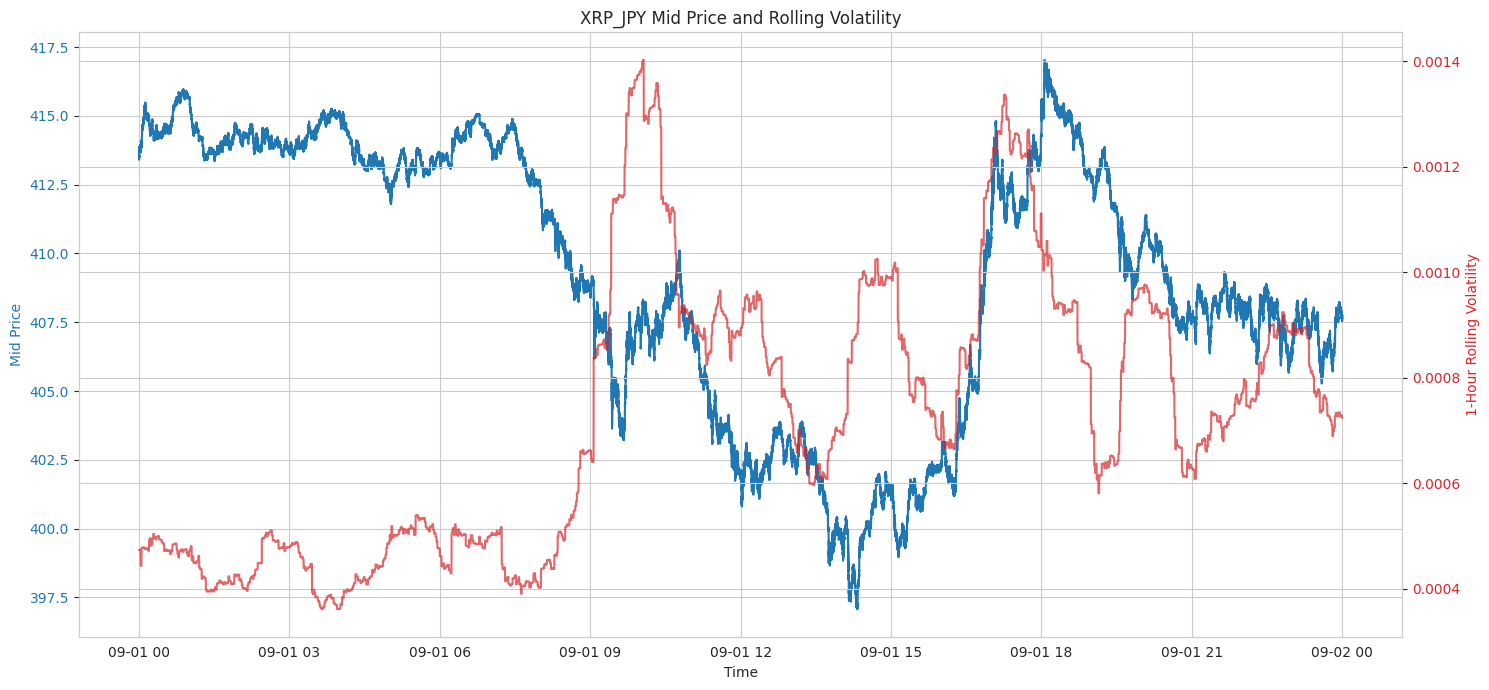

In [4]:
# Plot the mid-price and the calculated volatility
fig, ax1 = plt.subplots(figsize=(15, 7))

color = 'tab:blue'
ax1.set_xlabel('Time')
ax1.set_ylabel('Mid Price', color=color)
ax1.plot(df.index, df['mid'], color=color, label='Mid Price')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis
color = 'tab:red'
ax2.set_ylabel('1-Hour Rolling Volatility', color=color)
ax2.plot(df.index, df['volatility'], color=color, alpha=0.7, label='Volatility')
ax2.tick_params(axis='y', labelcolor=color)

plt.title(f'{MARKET.symbol.name} Mid Price and Rolling Volatility')
fig.tight_layout()
plt.show()

## 3. Define Barriers & Generate Labels

Now we use the calculated `volatility` series to define our dynamic barriers and generate labels. For simplicity, we will only generate labels for a **long scenario**.

In [5]:
# Define the profit-take and stop-loss levels for each timestamp dynamically
df['pt_pct'] = BARRIER_MULTIPLIER * df['volatility']
df['sl_pct'] = BARRIER_MULTIPLIER * df['volatility']

print("Profit-take and Stop-loss levels (in %):")
(df[['pt_pct', 'sl_pct']] * 100).describe()

Profit-take and Stop-loss levels (in %):


,pt_pct,sl_pct
count,175662.000000,175662.000000
mean,0.146041,0.146041
std,0.051147,0.051147
min,0.072289,0.072289
25%,0.097773,0.097773
50%,0.144441,0.144441
75%,0.181659,0.181659
max,0.280484,0.280484


In [6]:
@jit(nopython=True)
def _compute_labels_numba(timestamps: np.ndarray, ask_prices: np.ndarray, bid_prices: np.ndarray,
                          pt_pct: np.ndarray, sl_pct: np.ndarray, timeout_ns: int) -> np.ndarray:
    """
    Numba-optimized inner loop for triple-barrier label computation.
    All inputs must be numpy arrays.
    """
    n = len(timestamps)
    labels = np.zeros(n, dtype=np.int8)
    
    for i in range(n):
        entry_price = ask_prices[i]
        entry_ts = timestamps[i]
        timeout_ts = entry_ts + timeout_ns
        
        pt_level = pt_pct[i]
        sl_level = sl_pct[i]
        
        if np.isnan(entry_price) or np.isnan(pt_level) or np.isnan(sl_level):
            continue
        
        upper_barrier = entry_price * (1 + pt_level)
        lower_barrier = entry_price * (1 - sl_level)
        
        # Only search within timeout window
        for j in range(i + 1, n):
            if timestamps[j] > timeout_ts:
                break  # Timeout reached, label stays 0
            
            bid = bid_prices[j]
            if bid >= upper_barrier:
                labels[i] = 1  # Profit Take
                break
            elif bid <= lower_barrier:
                labels[i] = -1  # Stop Loss
                break
    
    return labels


def get_labels_with_dynamic_barriers(prices_df: pd.DataFrame, timeout_delta: pd.Timedelta,
                                      resample_interval: str = '1s') -> pd.DataFrame:
    """
    Computes triple-barrier labels for a long scenario using dynamic pt/sl levels.
    Optimized version: resamples data and uses numba JIT for fast computation.
    
    Args:
        prices_df: DataFrame with 'ask', 'bid', 'pt_pct', 'sl_pct' columns
        timeout_delta: Maximum time to wait for barrier hit
        resample_interval: Resample frequency to reduce data points (default 1s)
    """
    # Resample to reduce data points - use last value in each interval
    df_resampled = prices_df[['ask', 'bid', 'pt_pct', 'sl_pct']].resample(resample_interval).last().dropna()
    
    n = len(df_resampled)
    if n == 0:
        return pd.DataFrame({'label': []}, index=pd.DatetimeIndex([]))
    
    # Convert to numpy arrays for numba
    timestamps = df_resampled.index.values.astype('datetime64[ns]').astype(np.int64)
    ask_prices = df_resampled['ask'].values.astype(np.float64)
    bid_prices = df_resampled['bid'].values.astype(np.float64)
    pt_pct = df_resampled['pt_pct'].values.astype(np.float64)
    sl_pct = df_resampled['sl_pct'].values.astype(np.float64)
    timeout_ns = int(timeout_delta.total_seconds() * 1e9)
    
    # Run numba-optimized computation
    labels = _compute_labels_numba(timestamps, ask_prices, bid_prices, pt_pct, sl_pct, timeout_ns)
    
    return pd.DataFrame({'label': labels}, index=df_resampled.index)


# Generate the labels
print(f"Generating labels with {TIMEOUT_SEC}s timeout, resampled to {LABEL_RESAMPLE_INTERVAL}...")
print(f"Original data points: {len(df)}")
labels_df = get_labels_with_dynamic_barriers(df, TIMEOUT_DELTA, resample_interval=LABEL_RESAMPLE_INTERVAL)
print(f"Resampled data points: {len(labels_df)}")

# Join labels back - reindex to original df's index with forward fill
df['label'] = labels_df['label'].reindex(df.index, method='ffill')
print("Label generation complete.")
df[['mid', 'volatility', 'pt_pct', 'sl_pct', 'label']].head()

Generating labels with 45s timeout, resampled to 1s...
Original data points: 175662
Resampled data points: 86365
Label generation complete.


,mid,volatility,pt_pct,sl_pct,label
ts,,,,,
2025-09-01 00:00:00.230000019+09:00,413.533000,0.000474,0.000948,0.000948,0
2025-09-01 00:00:00.734999895+09:00,413.552933,0.000474,0.000948,0.000948,0
2025-09-01 00:00:01.240000010+09:00,413.518000,0.000474,0.000948,0.000948,0
2025-09-01 00:00:01.746000051+09:00,413.522000,0.000474,0.000948,0.000948,0
2025-09-01 00:00:01.983000040+09:00,413.546000,0.000474,0.000948,0.000948,0


## 4. Analyze Label Distribution

Finally, we analyze the outcomes. How many of our potential trades resulted in a win, a loss, or a timeout? This is critical for understanding if the barrier parameters are well-chosen. If 99% of labels are timeouts, the barriers might be too wide or the timeout too short.

Label Distribution Summary:
                       count  percentage
label                                   
Loss (SL = 2.0x Vol)   20221       11.51
Timeout (45s)         153884       87.60
Win (PT = 2.0x Vol)     1557        0.89


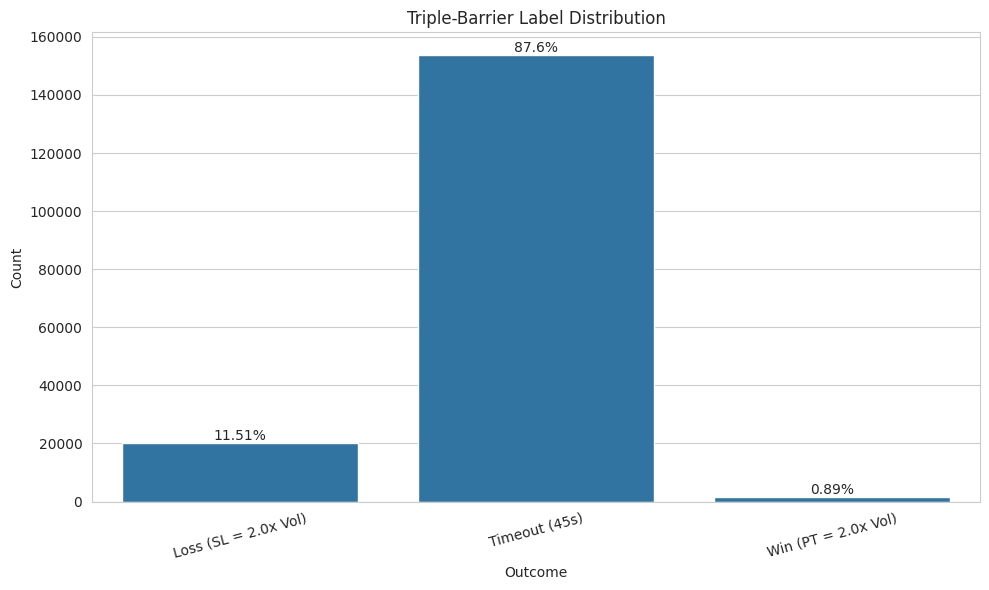

In [7]:
label_counts = df['label'].value_counts().sort_index()

# Create a mapping for human-readable labels
label_map = {
    1: f'Win (PT = {BARRIER_MULTIPLIER}x Vol)',
    -1: f'Loss (SL = {BARRIER_MULTIPLIER}x Vol)',
    0: f'Timeout ({TIMEOUT_SEC}s)'
}
label_counts.rename(index=label_map, inplace=True)

print("Label Distribution Summary:")
summary_df = pd.DataFrame({
    'count': label_counts,
    'percentage': (label_counts / label_counts.sum() * 100).round(2)
})
print(summary_df)

# Plot the distribution
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=summary_df.index, y=summary_df['count'])
ax.set_title('Triple-Barrier Label Distribution')
ax.set_ylabel('Count')
ax.set_xlabel('Outcome')

# Add percentage labels to the bars
for i, p in enumerate(ax.patches):
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2.,
            height + 0.1,
            f"{summary_df['percentage'].iloc[i]}%",
            ha="center", va="bottom")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()